In [1]:
from sklearn.cluster import DBSCAN, KMeans, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer

import torch

from pathlib import Path
import sys

import matplotlib.pyplot as plt

In [2]:
SRC = Path.cwd().parents[1]          # training/ -> restore_pipeline/ -> src/
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

In [ ]:
from restore_pipeline.dataprocessing.dataloading import (get_damaged_splits_dataloaders, 
                                                         get_splits_dataloaders, 
                                                         DataConfig,
                                                         SOBEL_TRANSFORM,
                                                         RESIZE_128)

from restore_pipeline.representation.train import TrainConfig, fit, damaged_reconstruction_loss, reconstruction_loss
from restore_pipeline.representation.models import (ConvAutoencoder, 
                                                    ConvOnlyAutoencoder,
                                                    DeepConvOnlyAutoencoder,
                                                    encode_loader)
from restore_pipeline.representation.plotting import plot_reconstructions
from restore_pipeline.representation.utils import encode_loader_gram

from restore_pipeline.clustering.plotting import umap_project, plot_clusters_2d
from restore_pipeline.clustering.utils import kmeans_sweep
from restore_pipeline.clustering.plotting import plot_kmeans_sweep

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
data_cfg = DataConfig(
    processed_path=Path("../data/wikiart_train_processed"),
    cache_dir="../data",
    transform_train=RESIZE_128,
    transform_val=RESIZE_128,
    transform_test=RESIZE_128,
    transform_full=RESIZE_128,
)
train_dmg, val_dmg, test_dmg = get_damaged_splits_dataloaders(data_cfg, mix=True)
train_clean, val_clean, test_clean = get_splits_dataloaders(data_cfg)

In [6]:
from torch.utils.data import DataLoader, Subset

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(train_clean.dataset), generator=generator)[:20_000].tolist()

train_clean_small = DataLoader(
    Subset(train_clean.dataset, indices),
    batch_size=train_clean.batch_size,
    shuffle=True,
    num_workers=train_clean.num_workers,
    pin_memory=train_clean.pin_memory,
)


train_clean = train_clean_small

In [7]:
from torch.utils.data import DataLoader, Subset

n_paintings = len(train_dmg.dataset) // 2                      # ConcatDataset([clean, damaged]): two halves of equal length
generator = torch.Generator().manual_seed(42)
paintings = torch.randperm(n_paintings, generator=generator)[:10_000]

indices = torch.cat([paintings, paintings + n_paintings]).tolist()

train_dmg_small = DataLoader(
    Subset(train_dmg.dataset, indices),
    batch_size=train_dmg.batch_size,
    shuffle=True,
    num_workers=train_dmg.num_workers,
    pin_memory=train_dmg.pin_memory,
)


train_dmg = train_dmg_small

# Model definition

In [8]:
model = DeepConvOnlyAutoencoder(in_channels=3, out_channels=3) 
model.to(device)
train_cfg = TrainConfig(epochs=10)
history = fit(model, train_dmg, val_dmg, train_cfg, loss_fn = damaged_reconstruction_loss)

plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/313 [00:14<?, ?it/s]

KeyboardInterrupt: 

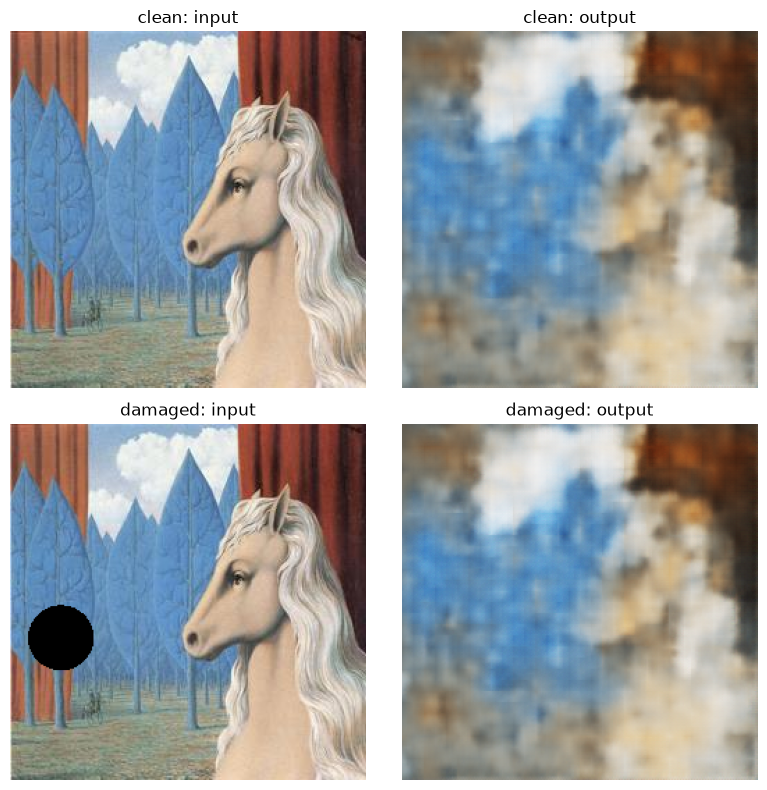

In [ ]:
n_val = len(val_clean.dataset)
i = 1521
clean = val_clean.dataset[i]["image"]
damaged = val_dmg.dataset[i + n_val]["image"]     # mix=True: damaged copies come after the clean ones

plot_reconstructions(model, [clean, damaged], device, titles=["clean", "damaged"])

In [ ]:
embed_dmg = encode_loader(model, train_dmg, device)
embed_clean = encode_loader(model, train_clean, device)

In [ ]:

# embed_clean = encode_loader_gram(model.encoder, train_clean, device)

In [ ]:
print(embed_clean.shape)

(20000, 1024)


# Clustering

K-means sweep:   0%|          | 0/10 [00:20<?, ?it/s]

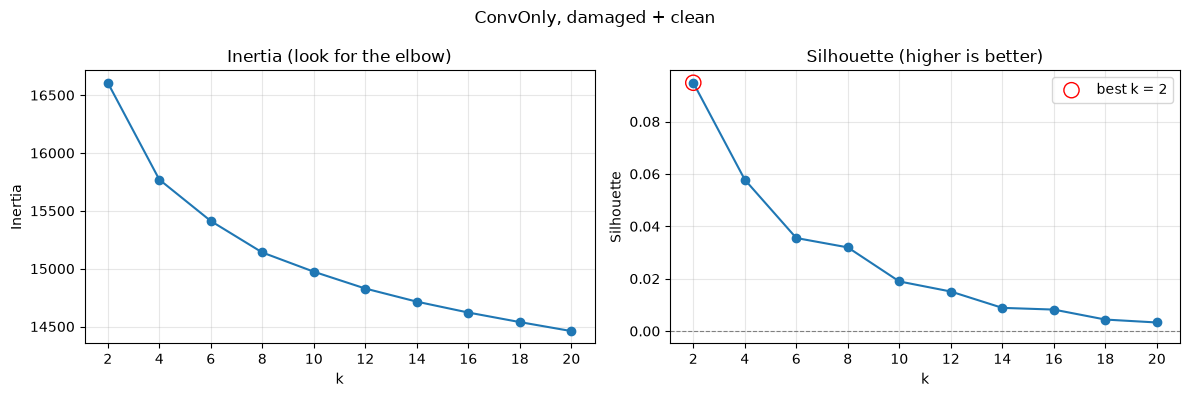

In [ ]:
pipe = make_pipeline(
    # PCA(n_components=256, whiten=False, random_state=42),
    Normalizer(norm="l2"),
    # KMeans(n_clusters=8, n_init=10, random_state=42),
)
features_clean = pipe.fit_transform(embed_clean)
# features_clean = embed_clean
sweep = kmeans_sweep(features_clean, range(2, 21, 2))
plot_kmeans_sweep(sweep, title="ConvOnly, damaged + clean")
plt.show()

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


20000


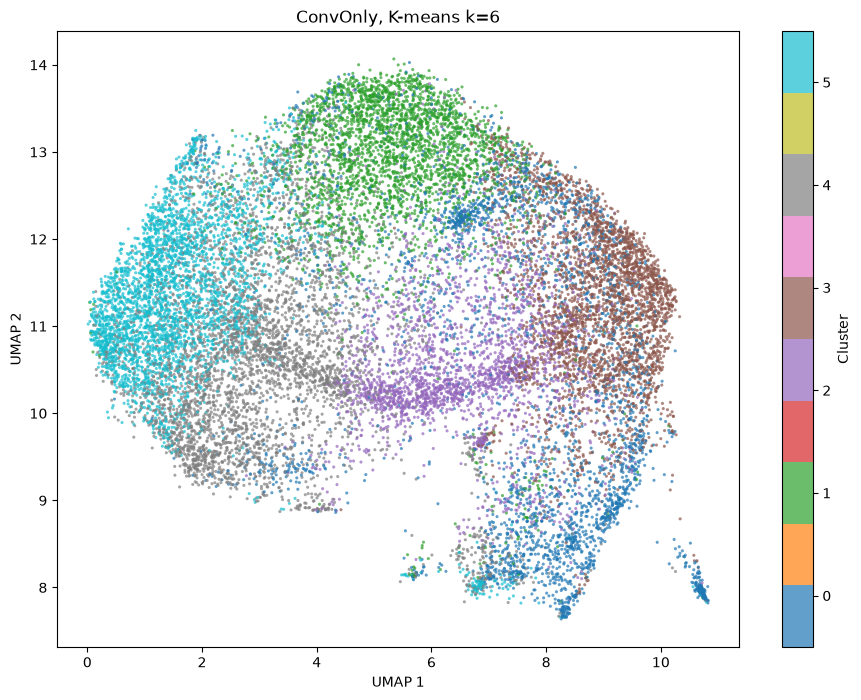

In [ ]:
K = 6
labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(features_clean)

embedding_2d, idx = umap_project(features_clean)
print(len(embedding_2d))

plot_clusters_2d(embedding_2d, labels[idx], title=f"ConvOnly, K-means k={K}")
plt.show()

In [ ]:
from restore_pipeline.dataprocessing.dataloading import get_splits, get_splits_dataloaders

# Same split as training, but no shuffling, so row i is the same painting everywhere.
encode_cfg = DataConfig(
    processed_path=Path("../data/wikiart_train_processed"),
    cache_dir="../data",
    shuffle_train=False,
    # transform_train=SOBEL_TRANSFORM,
    # transform_val=SOBEL_TRANSFORM,
    # transform_test=SOBEL_TRANSFORM,
    # transform_full=SOBEL_TRANSFORM,
)

# 1. Embeddings, in dataset order
train_ordered, _, _ = get_splits_dataloaders(encode_cfg)
embed = encode_loader(model, train_ordered, device)

# 2. Cluster (keep the fitted KMeans so it can be saved together with pipe2)
pipe2 = make_pipeline(
    # PCA(n_components=256, whiten=False, random_state=42),
    Normalizer(norm="l2"),
)
features = pipe2.fit_transform(embed)
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(features)
labels = kmeans.labels_

# 3. Metadata, in the same order (only the small text columns, images are not decoded)
ds_train, _, _ = get_splits(encode_cfg)
meta = ds_train.select_columns(["style", "artist"]).to_pandas()

# 4. Align and drop paintings with no style
has_style = meta["style"].notna().to_numpy()
y_true = meta["style"][has_style].to_numpy()
y_pred = labels[has_style]

assert len(meta) == len(labels), "embeddings and metadata are not the same split"


In [ ]:
# import joblib

# CHECKPOINT_DIR = Path("checkpoints")
# CHECKPOINT_DIR.mkdir(exist_ok=True)

# # PCA -> Normalizer -> KMeans, all fitted in the cell above: embeddings in, cluster labels out.
# clusterer = make_pipeline(*[step for _, step in pipe2.steps], kmeans)
# joblib.dump(clusterer, CHECKPOINT_DIR / f"sobel_conv_only_kmeans{K}.joblib")

In [ ]:
print(ds_train.column_names)

['title', 'artist', 'date', 'genre', 'style', 'filename', 'image']


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_mutual_info_score, normalized_mutual_info_score

styles = pd.Series(ds_train["artist"])            # must be in the same row order as `labels`
has_style = styles.notna().to_numpy()            # preprocessing set some styles to None

y_true = styles[has_style].to_numpy()
y_pred = labels[has_style]

nmi = normalized_mutual_info_score(y_true, y_pred)
ami = adjusted_mutual_info_score(y_true, y_pred)
print(f"NMI = {nmi:.3f} | AMI = {ami:.3f} | on {has_style.sum()} of {len(labels)} paintings")


NMI = 0.090 | AMI = 0.076 | on 82301 of 82321 paintings


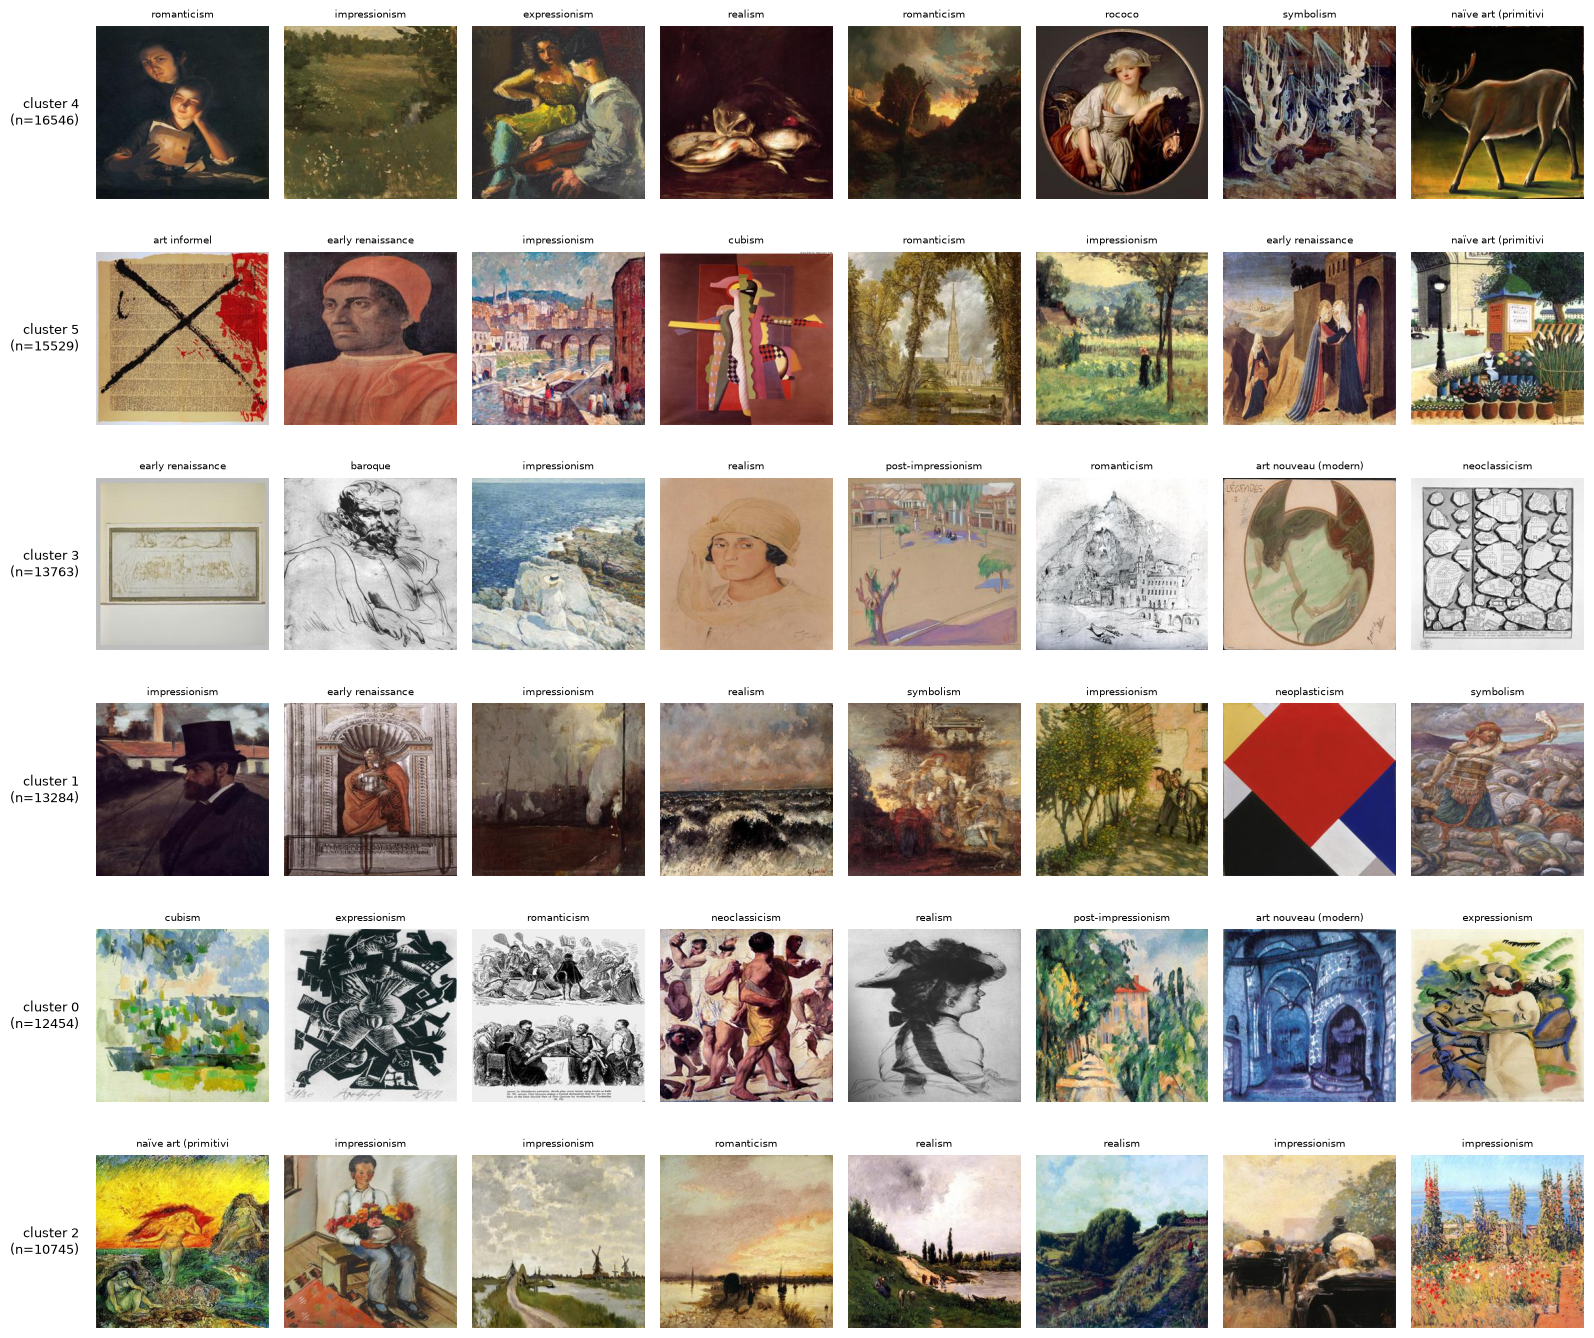

In [ ]:
from restore_pipeline.clustering.plotting import plot_cluster_samples

plot_cluster_samples(ds_train, labels, n_per_cluster=8, captions=meta["style"])


In [ ]:
# from restore_pipeline.representation.train import save_checkpoint

# CHECKPOINT_DIR = Path("checkpoints")
# CHECKPOINT_DIR.mkdir(exist_ok=True)

# save_checkpoint(model, CHECKPOINT_DIR / "sobel_conv_only.pt", history=history)